# 05 — Evaluation: Family A vs. Family B
Combines the cross-validated results from `03_imbalance_classification.ipynb`
and `04_anomaly_detection.ipynb`, tests whether the differences between
them are statistically significant, and answers the study's core
research questions (RQ3, RQ5).

Significance is judged with the **corrected resampled t-test**
(Nadeau & Bengio, 2003) and intervals with the matching corrected
t-based CI, because repeated-CV fold scores are not independent.
The Wilcoxon / raw-fold Friedman results are still saved as an
(optimistic) sensitivity check.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pickle
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

from src.evaluation import (
    friedman_test, pairwise_wilcoxon, pairwise_corrected_ttest,
    cv_split_sizes, N_SPLITS
)
from src.reporting import TABLES_DIR, save_figure, save_table, save_json

# CV in 03/04 runs on the 80% training split, so the corrected tests
# need that split's per-fold train/test sizes.
TEST_SIZE = 0.2
RANDOM_STATE = 42
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "tracer_study_processed.csv")
train_df, _ = train_test_split(df, test_size=TEST_SIZE, random_state=RANDOM_STATE,
                               stratify=df["employment_status"])
N_TRAIN, N_TEST = cv_split_sizes(len(train_df), N_SPLITS)
print(f"CV on {len(train_df)} rows: n_train={N_TRAIN:.0f}, n_test={N_TEST:.0f} per fold")

CV on 125 rows: n_train=100, n_test=25 per fold


## Load results from both families

In [2]:
family_a_summary = pd.read_csv(TABLES_DIR / "family_a_cv_summary.csv", index_col=0)
family_b_summary = pd.read_csv(TABLES_DIR / "family_b_cv_summary.csv", index_col=0)

with open(TABLES_DIR / "family_a_raw_scores.pkl", "rb") as f:
    family_a_scores = pickle.load(f)
with open(TABLES_DIR / "family_b_raw_scores.pkl", "rb") as f:
    family_b_scores = pickle.load(f)

all_scores = {**family_a_scores, **family_b_scores}
combined_summary = pd.concat([family_a_summary, family_b_summary]).sort_values(
    "pr_auc", ascending=False
)

## RQ3 — Which approach achieves the highest PR-AUC?

,accuracy,precision,recall,f1,pr_auc,accuracy_std,precision_std,recall_std,f1_std,pr_auc_std,pr_auc_ci_low,pr_auc_ci_high,pr_auc_corrected_ci_low,pr_auc_corrected_ci_high
A4_ADASYN_RandomForest,0.759,0.368,0.228,0.266,0.440,0.070,0.288,0.150,0.171,0.114,0.408,0.471,0.319,0.560
A3_SMOTE_RandomForest,0.758,0.358,0.256,0.276,0.432,0.069,0.280,0.192,0.186,0.114,0.401,0.464,0.312,0.552
A1_RandomForest_ClassWeighted,0.731,0.352,0.364,0.343,0.426,0.081,0.189,0.199,0.167,0.126,0.392,0.461,0.293,0.558
A2_XGBoost_ScalePosWeight,0.690,0.298,0.352,0.302,0.386,0.084,0.192,0.190,0.144,0.136,0.350,0.426,0.243,0.529
B3_LocalOutlierFactor,0.765,0.253,0.088,0.125,0.302,0.047,0.338,0.099,0.143,0.117,0.271,0.335,0.179,0.426
B1_IsolationForest,0.557,0.253,0.620,0.357,0.287,0.106,0.092,0.241,0.129,0.103,0.259,0.316,0.178,0.395
B2_OneClassSVM,0.546,0.140,0.236,0.172,0.264,0.096,0.090,0.153,0.107,0.100,0.237,0.292,0.158,0.370


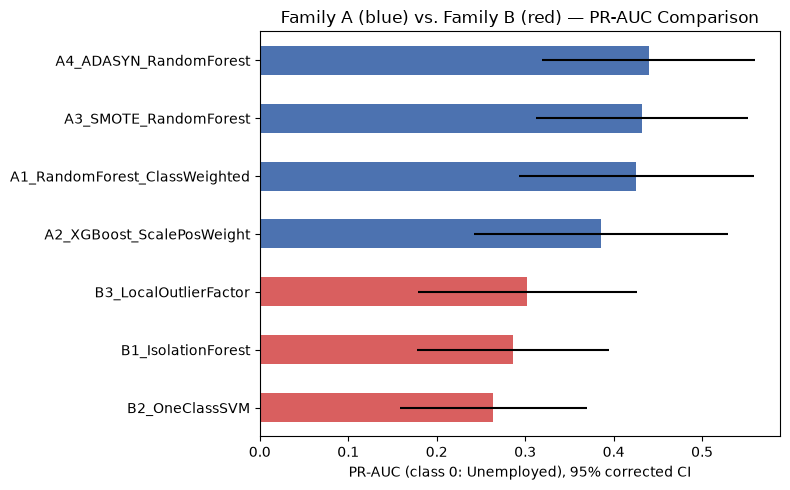

In [3]:
display(combined_summary.round(3))
save_table(combined_summary, "combined_cv_summary")

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#4c72b0" if name in family_a_summary.index else "#d95f5f"
          for name in combined_summary.index]
xerr = [
    combined_summary["pr_auc"] - combined_summary["pr_auc_corrected_ci_low"],
    combined_summary["pr_auc_corrected_ci_high"] - combined_summary["pr_auc"],
]
combined_summary["pr_auc"].plot(kind="barh", ax=ax, color=colors, xerr=xerr)
ax.set_xlabel("PR-AUC (class 0: Unemployed), 95% corrected CI")
ax.set_title("Family A (blue) vs. Family B (red) — PR-AUC Comparison")
ax.invert_yaxis()
plt.tight_layout()
save_figure(fig, "combined_pr_auc_comparison")
plt.show()

## RQ5 — Are unemployed graduates better characterized as a minority class or as anomalous observations?

Answered by the Friedman test (is there a significant difference
among ALL models' cross-validated PR-AUC?) followed by pairwise
corrected resampled t-tests (which specific pairs differ?),
Bonferroni-corrected across 21 pairs at α=0.05.

In [4]:
# Primary: blocks are the 10 CV repeats (fold scores averaged within
# each repeat), since the 50 raw folds aren't independent blocks.
friedman_result = friedman_test(all_scores, n_splits=N_SPLITS)
friedman_raw = friedman_test(all_scores)
print("Friedman test (all models, per-repeat blocks):", friedman_result)
print("Friedman test (raw folds, optimistic):       ", friedman_raw)
save_json({"per_repeat": friedman_result, "raw_folds": friedman_raw}, "friedman_result");

Friedman test (all models, per-repeat blocks): {'statistic': np.float64(51.68571428571431), 'p_value': np.float64(2.1568480417805716e-09), 'significant_at_0.05': np.True_}
Friedman test (raw folds, optimistic):        {'statistic': np.float64(94.96285714285727), 'p_value': np.float64(2.8143825625526403e-18), 'significant_at_0.05': np.True_}


In [5]:
# Primary: Nadeau-Bengio corrected resampled t-test.
corrected_results = pairwise_corrected_ttest(
    all_scores, N_TRAIN, N_TEST, alpha=0.05, correction="bonferroni"
)
display(corrected_results.round(4))
save_table(corrected_results, "pairwise_corrected_ttest", index=False)

# Sensitivity check only — treats folds as independent, so optimistic.
wilcoxon_results = pairwise_wilcoxon(all_scores, alpha=0.05, correction="bonferroni")
save_table(wilcoxon_results, "pairwise_wilcoxon", index=False);

,model_a,model_b,mean_diff,statistic,p_value,significant
16,A4_ADASYN_RandomForest,B2_OneClassSVM,0.1755,2.1775,0.0343,False
13,A3_SMOTE_RandomForest,B2_OneClassSVM,0.1682,2.0378,0.0470,False
15,A4_ADASYN_RandomForest,B1_IsolationForest,0.1529,1.8892,0.0648,False
12,A3_SMOTE_RandomForest,B1_IsolationForest,0.1456,1.8460,0.0709,False
4,A1_RandomForest_ClassWeighted,B2_OneClassSVM,0.1616,1.8359,0.0724,False
3,A1_RandomForest_ClassWeighted,B1_IsolationForest,0.1390,1.7257,0.0907,False
17,A4_ADASYN_RandomForest,B3_LocalOutlierFactor,0.1372,1.5318,0.1320,False
20,B2_OneClassSVM,B3_LocalOutlierFactor,-0.0383,-1.4146,0.1635,False
14,A3_SMOTE_RandomForest,B3_LocalOutlierFactor,0.1298,1.4063,0.1660,False
5,A1_RandomForest_ClassWeighted,B3_LocalOutlierFactor,0.1233,1.2638,0.2123,False


**Reading this table:** each row's `p_value` comes from the corrected
resampled t-test (Nadeau & Bengio, 2003), which inflates the variance
of the fold-score differences by `(1/k + n_test/n_train)` instead of
`1/k`. Repeated-CV folds share most of their training rows, so a test
that treats the 50 fold scores as independent (the Wilcoxon test
saved to `pairwise_wilcoxon.csv`) understates the variance and
overstates significance. Each p-value is compared against a
Bonferroni-corrected α (0.05 / 21 pairs = 0.00238).

In [6]:
FAMILY_A = set(family_a_summary.index)
FAMILY_B = set(family_b_summary.index)

def which_family(model_name):
    return "A" if model_name in FAMILY_A else "B"

wilcoxon_sig = {
    (r.model_a, r.model_b): r.significant for r in wilcoxon_results.itertuples()
}

corrected_results["family_a"] = corrected_results["model_a"].apply(which_family)
corrected_results["family_b"] = corrected_results["model_b"].apply(which_family)
corrected_results["wilcoxon_significant"] = [
    wilcoxon_sig[(a, b)] for a, b in zip(corrected_results["model_a"], corrected_results["model_b"])
]

cols = ["model_a", "model_b", "mean_diff", "p_value", "significant", "wilcoxon_significant"]
cross_family = corrected_results[corrected_results["family_a"] != corrected_results["family_b"]]
print("Cross-family comparisons (classification vs. anomaly detection):")
display(cross_family[cols].round(4))
save_table(cross_family[cols], "cross_family_tests", index=False);

Cross-family comparisons (classification vs. anomaly detection):


,model_a,model_b,mean_diff,p_value,significant,wilcoxon_significant
16,A4_ADASYN_RandomForest,B2_OneClassSVM,0.1755,0.0343,False,True
13,A3_SMOTE_RandomForest,B2_OneClassSVM,0.1682,0.0470,False,True
15,A4_ADASYN_RandomForest,B1_IsolationForest,0.1529,0.0648,False,True
12,A3_SMOTE_RandomForest,B1_IsolationForest,0.1456,0.0709,False,True
4,A1_RandomForest_ClassWeighted,B2_OneClassSVM,0.1616,0.0724,False,True
3,A1_RandomForest_ClassWeighted,B1_IsolationForest,0.1390,0.0907,False,True
17,A4_ADASYN_RandomForest,B3_LocalOutlierFactor,0.1372,0.1320,False,True
14,A3_SMOTE_RandomForest,B3_LocalOutlierFactor,0.1298,0.1660,False,True
5,A1_RandomForest_ClassWeighted,B3_LocalOutlierFactor,0.1233,0.2123,False,True
9,A2_XGBoost_ScalePosWeight,B2_OneClassSVM,0.1219,0.2312,False,True


## Nested cross-validation — A1

`nested_cross_validate()` in `src/evaluation.py` wraps model fitting in
an outer repeated-stratified-K-fold loop, with hyperparameter selection
(inner-fold `GridSearchCV`) happening independently inside each outer
fold — so tuning never leaks into the score.

A one-off run for A1 (5-fold x 3-repeat outer, 3-fold inner grid search
over `n_estimators`/`max_depth`) gave **PR-AUC = 0.315 ± 0.117**
(`reports/tables/family_a_nested_cv_summary.csv`), vs. 0.426 for A1 in
the simple setup above. Two caveats:

- The simple-CV A1 uses Random Forest defaults (no tuning), so the gap
  is not tuning leakage. It more likely reflects the different data
  (full 157 rows vs. the 125-row training split), fold layout, and the
  noise of inner-fold grid search with ~4 minority cases per inner fold.
- That run isn't captured in a notebook, and its saved 95% CI
  ([0.259, 0.376]) is a percentile bootstrap over the 15 outer folds, so
  it shares the too-narrow problem the corrected CI fixes.

## Summary

- **Best model by simple CV:** A4 — ADASYN + Random Forest (PR-AUC = 0.440,
  95% corrected CI [0.319, 0.560]), narrowly ahead of A3 (0.432) and A1
  (0.426). The four Family A models are statistically indistinguishable.
- **RQ3 answer:** every Family A model has a higher mean CV PR-AUC than
  every Family B model (Family A: 0.386–0.440; Family B: 0.264–0.302), and
  all 12 cross-family mean differences favor Family A (+0.08 to +0.18).
- **RQ5 answer — direction consistent, significance not established.**
  The Friedman test is significant (per-repeat blocks: χ²=51.69,
  p=2.2×10⁻⁹), but no pairwise comparison survives the corrected
  resampled t-test, even before Bonferroni correction for most pairs
  (smallest p = 0.034, A4 vs. B2; Bonferroni α = 0.00238). The earlier
  Wilcoxon result (A1/A3/A4 significantly beating every Family B model)
  came from treating the 50 overlapping CV folds as independent samples.
  The evidence therefore *leans toward* the minority-class framing but
  does not show it is reliably better at n=157 / 31 unemployed cases.
- **Holdout caveat:** on the 32-row holdout (6 unemployed), A4 scores
  PR-AUC 0.171 (below the 0.1875 base rate) while B3 scores 0.289 — the
  reverse of the CV ranking. With 6 positives this is mostly noise, but it
  reinforces that the ranking is not yet settled.
- **Open item:** a fully nested, notebook-captured evaluation for all
  seven models would give the most defensible comparison.